<a href="https://colab.research.google.com/github/JamesFrank-Space/Solar-Wind-Prediction-Study/blob/main/Copy_of_solar_wind_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("My Solar Wind Research Project")
print("Researcher: Jmaes Frank")
print("Start Date: 20 March, 2026")

My Solar Wind Research Project
Researcher: Jmaes Frank
Start Date: 20 March, 2026


In [ ]:

import json
import urllib.request
import pandas as pd

url = "https://services.swpc.noaa.gov/json/rtsw/rtsw_wind_1m.json"

request = urllib.request.Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(request, timeout=30) as response:
    solar_wind_data = json.loads(response.read().decode("utf-8"))

df = pd.DataFrame(solar_wind_data)
df["time_tag"] = pd.to_datetime(df["time_tag"], errors="coerce")

for column in ["proton_density", "proton_speed", "proton_temperature"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("NOAA solar wind data downloaded successfully.")
print("Dataset dimensions:", df.shape)
display(df.head())


In [ ]:

# STEP 2: Plot the three solar wind measurements over time

import matplotlib.pyplot as plt

plot_df = df.sort_values("time_tag").copy()

measurements = [
    ("proton_speed", "Proton speed (km/s)"),
    ("proton_density", "Proton density (particles/cm³)"),
    ("proton_temperature", "Proton temperature (K)")
]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, (column, label) in zip(axes, measurements):
    for source, group in plot_df.groupby("source"):
        group = group.dropna(subset=["time_tag", column])
        ax.plot(group["time_tag"], group[column],
                marker=".", markersize=2, linewidth=0.8,
                label=source)

    ax.set_ylabel(label)
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
fig.suptitle("Solar Wind Measurements from Different Sources")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 3: Check data quality

print("Missing values in key measurements:")
print(df[[
    "proton_speed",
    "proton_density",
    "proton_temperature"
]].isna().sum())

print("\nRepeated timestamps:", df["time_tag"].duplicated().sum())

print("\nMeasurements by source:")
print(df["source"].value_counts())


In [ ]:

# STEP 4: Inspect repeated timestamps

print("Example records with repeated timestamps:")

repeated = df[df["time_tag"].duplicated(keep=False)]

display(
    repeated[
        ["time_tag", "source", "proton_speed",
         "proton_density", "proton_temperature"]
    ].sort_values("time_tag").head(15)
)


In [ ]:

# STEP 5: Prepare ACE observations for analysis

ace_df = df[df["source"] == "ACE"].copy()

ace_df = ace_df.sort_values("time_tag")

# Keep only the time and three main measurements
ace_df = ace_df[
    ["time_tag", "proton_speed",
     "proton_density", "proton_temperature"]
]

print("ACE dataset dimensions:", ace_df.shape)
print("\nMissing values:")
print(ace_df.isna().sum())

print("\nFirst five ACE observations:")
display(ace_df.head())


In [ ]:

# STEP 6: Check gaps between ACE observations

ace_df["time_gap_minutes"] = (
    ace_df["time_tag"].diff().dt.total_seconds() / 60
)

print("Time gap in minutes between consecutive observations:")
print(ace_df["time_gap_minutes"].value_counts().sort_index())

print("\nLargest time gaps:")
display(
    ace_df.nlargest(10, "time_gap_minutes")[
        ["time_tag", "time_gap_minutes"]
    ]
)


In [ ]:

# STEP 7: Test linear interpolation on hidden measurements

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Use ACE proton speed, arranged at one-minute intervals
speed = (
    ace_df.drop_duplicates("time_tag")
    .set_index("time_tag")["proton_speed"]
    .sort_index()
)

full_time = pd.date_range(
    start=speed.index.min(),
    end=speed.index.max(),
    freq="1min"
)

speed = speed.reindex(full_time)

# Only test values that were actually measured
known_positions = np.flatnonzero(speed.notna().to_numpy())

# Hide 15% of known measurements at random
rng = np.random.default_rng(42)
n_hide = max(1, int(0.15 * len(known_positions)))
hidden_positions = rng.choice(
    known_positions, size=n_hide, replace=False
)

true_values = speed.iloc[hidden_positions].copy()
test_speed = speed.copy()
test_speed.iloc[hidden_positions] = np.nan

# Estimate the hidden values using interpolation
predictions = test_speed.interpolate(
    method="linear", limit_area="inside"
).iloc[hidden_positions]

# Compare predictions with the real measurements
valid = predictions.notna()

mae = mean_absolute_error(
    true_values[valid],
    predictions[valid]
)

print("Hidden measurements:", n_hide)
print("Successfully predicted:", int(valid.sum()))
print("Mean Absolute Error:", round(mae, 2), "km/s")


In [ ]:

# STEP 8: Compare interpolation with forward fill

# Recreate the same hidden measurements
test_speed = speed.copy()
test_speed.iloc[hidden_positions] = np.nan

# Method 1: Linear interpolation
interpolation_predictions = test_speed.interpolate(
    method="linear", limit_area="inside"
).iloc[hidden_positions]

# Method 2: Forward fill
forward_fill_predictions = test_speed.ffill().iloc[hidden_positions]

# Compare both methods on the same hidden values
true_values = speed.iloc[hidden_positions]

interpolation_mae = mean_absolute_error(
    true_values, interpolation_predictions
)

forward_fill_mae = mean_absolute_error(
    true_values, forward_fill_predictions
)

print("Prediction comparison for proton speed")
print("---------------------------------------")
print("Linear interpolation MAE:",
      round(interpolation_mae, 2), "km/s")
print("Forward fill MAE:",
      round(forward_fill_mae, 2), "km/s")


In [ ]:
%whos

In [ ]:
# Test a continuous gap of five missing minutes

# Find seven consecutive valid observations:
# one before the gap, five inside it, and one after it
valid_seven = speed.notna().rolling(window=7).sum().eq(7)
candidate_ends = np.flatnonzero(valid_seven.to_numpy())

if len(candidate_ends) == 0:
    print("No suitable block found. We need to check the data.")
else:
    # Select a block near the middle of the data
    end_pos = candidate_ends[len(candidate_ends) // 2]
    start_pos = end_pos - 6

    # Hide the five middle observations
    gap_positions = np.arange(start_pos + 1, start_pos + 6)

    test_speed_gap = speed.copy()
    test_speed_gap.iloc[gap_positions] = np.nan

    # Method 1: Linear interpolation
    interpolation_gap = test_speed_gap.interpolate(
        method="linear", limit_area="inside"
    ).iloc[gap_positions]

    # Method 2: Forward fill
    forward_fill_gap = test_speed_gap.ffill().iloc[gap_positions]

    # Recover the original values for evaluation
    true_gap_values = speed.iloc[gap_positions]

    # Calculate the errors
    interpolation_gap_mae = mean_absolute_error(
        true_gap_values, interpolation_gap
    )

    forward_fill_gap_mae = mean_absolute_error(
        true_gap_values, forward_fill_gap
    )

    print("Five-minute gap test")
    print("--------------------")
    print("Linear interpolation MAE:",
          round(interpolation_gap_mae, 2), "km/s")
    print("Forward fill MAE:",
          round(forward_fill_gap_mae, 2), "km/s")

    print("\nOriginal and estimated values:")
    print("Actual:", true_gap_values.to_list())
    print("Interpolation:", interpolation_gap.to_list())
    print("Forward fill:", forward_fill_gap.to_list())

In [ ]:
%whos

In [ ]:
# Predict the next minute's proton speed
# using the current minute's speed

forecast_data = pd.DataFrame({
    "current_speed": speed,
    "next_speed": speed.shift(-1)
}).dropna()

# Keep the data in chronological order
split = int(len(forecast_data) * 0.8)
test = forecast_data.iloc[split:]

# Baseline prediction: speed stays the same
predicted_speed = test["current_speed"]
actual_speed = test["next_speed"]

# Measure prediction error
baseline_mae = mean_absolute_error(
    actual_speed, predicted_speed
)

print("One-minute solar wind speed prediction")
print("Test observations:", len(test))
print("Baseline MAE:", round(baseline_mae, 2), "km/s")

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    actual_speed.index,
    actual_speed,
    label="Actual speed"
)

plt.plot(
    predicted_speed.index,
    predicted_speed,
    label="Predicted speed",
    alpha=0.8
)

plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.title("Actual and Predicted Solar Wind Speed")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Prepare data for one-minute-ahead prediction

prediction_data = pd.DataFrame({
    "speed_t": speed,
    "speed_t1": speed.shift(1),
    "speed_t2": speed.shift(2),
    "speed_t3": speed.shift(3),
    "speed_t4": speed.shift(4),
    "speed_t5": speed.shift(5),
    "target": speed.shift(-1)
}).dropna()

print("Prediction data prepared")
print("Number of observations:", len(prediction_data))
display(prediction_data.head())

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Select the input features
features = [
    "speed_t",
    "speed_t1",
    "speed_t2",
    "speed_t3",
    "speed_t4",
    "speed_t5"
]

X = prediction_data[features]
y = prediction_data["target"]

# Keep the observations in time order
split = int(len(prediction_data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# Train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Predict proton speed
rf_predictions = model.predict(X_test)

# Calculate prediction errors
rf_mae = mean_absolute_error(y_test, rf_predictions)

# Compare with the baseline on the same test observations
baseline_predictions = X_test["speed_t"]
baseline_mae_same_test = mean_absolute_error(
    y_test, baseline_predictions
)

print("Random Forest solar wind prediction")
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Baseline MAE:", round(baseline_mae_same_test, 2), "km/s")
print("Random Forest MAE:", round(rf_mae, 2), "km/s")

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    y_test,
    label="Actual speed"
)

plt.plot(
    y_test.index,
    rf_predictions,
    label="Random Forest prediction"
)

plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.title("Random Forest: Actual vs Predicted Solar Wind Speed")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Train a Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict the test observations
linear_predictions = linear_model.predict(X_test)

# Calculate the prediction error
linear_mae = mean_absolute_error(
    y_test, linear_predictions
)

print("Linear Regression solar wind prediction")
print("Baseline MAE:", round(baseline_mae_same_test, 2), "km/s")
print("Random Forest MAE:", round(rf_mae, 2), "km/s")
print("Linear Regression MAE:", round(linear_mae, 2), "km/s")

In [ ]:
# Check the time intervals between measurements

time_gaps = speed.index.to_series().diff()

print("Total observations:", len(speed))
print("Time intervals longer than one minute:",
      (time_gaps > pd.Timedelta(minutes=1)).sum())

print("\nLargest time intervals:")
print(time_gaps.sort_values(ascending=False).head(10))

In [ ]:
# Dataset overview

print("DATASET CHARACTERISATION")
print("=" * 45)

print("\n1. Dataset dimensions")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. Available variables")
print(df.columns.tolist())

print("\n3. Spacecraft sources")
print(df["source"].value_counts(dropna=False))

print("\n4. Missing values")
print(df.isnull().sum().sort_values(ascending=False))

print("\n5. Summary statistics")
display(df.describe(include="all"))

print("\n6. Time coverage")
print("First observation:", df["time_tag"].min())
print("Last observation:", df["time_tag"].max())

In [ ]:
# SPACECRAFT DATA COMPARISON

print("SPACECRAFT DATA COMPARISON")
print("=" * 50)

source_analysis = df.groupby("source").agg(
    records=("proton_speed", "size"),
    valid_speed=("proton_speed", "count"),
    mean_speed=("proton_speed", "mean"),
    median_speed=("proton_speed", "median"),
    speed_std=("proton_speed", "std"),
    minimum_speed=("proton_speed", "min"),
    maximum_speed=("proton_speed", "max"),
    first_observation=("time_tag", "min"),
    last_observation=("time_tag", "max")
)

display(source_analysis.round(2))

print("\nACTIVE STATUS BY SPACECRAFT")
display(pd.crosstab(df["source"], df["active"]))

print("\nTIMESTAMP OVERLAP")
print("Total unique timestamps:", df["time_tag"].nunique())
print("Records with timestamps shared by multiple sources:",
      df["time_tag"].duplicated(keep=False).sum())

In [ ]:
# CREATE THE PRIMARY SOLAR WIND DATASET

solar_df = df[df["source"] == "SOLAR1"].copy()

# Keep valid proton speed measurements
solar_df = solar_df.dropna(subset=["proton_speed"])

# Sort measurements by observation time
solar_df = solar_df.sort_values("time_tag")

# Remove duplicate timestamps, retaining the first record
solar_df = solar_df.drop_duplicates(
    subset=["time_tag"],
    keep="first"
)

print("PRIMARY DATASET: SOLAR-1")
print("=" * 45)

print("Total observations:", len(solar_df))
print("First observation:", solar_df["time_tag"].min())
print("Last observation:", solar_df["time_tag"].max())

print("\nProton speed statistics:")
display(solar_df["proton_speed"].describe())

print("\nMissing values:")
display(solar_df.isnull().sum())

In [ ]:
# SOLAR WIND PROTON SPEED TIME SERIES

import matplotlib.pyplot as plt
import pandas as pd

solar_df["time_tag"] = pd.to_datetime(solar_df["time_tag"])

solar_df = solar_df.sort_values("time_tag")

plt.figure(figsize=(14, 6))

plt.scatter(
    solar_df["time_tag"],
    solar_df["proton_speed"],
    s=10,
    label="SOLAR-1 measurements"
)

plt.xlabel("Observation Time")
plt.ylabel("Proton Speed (km/s)")

plt.title(
    "Solar Wind Proton Speed Observed by SOLAR-1"
)

plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# INVESTIGATE TIME INTERVALS

time_difference = solar_df["time_tag"].diff().dropna()

print("TIME INTERVAL ANALYSIS")
print("=" * 40)

print("Median interval:",
      time_difference.median())

print("Intervals longer than one minute:",
      (time_difference > pd.Timedelta(minutes=1)).sum())

print("Largest time gap:",
      time_difference.max())

print("\nMost common time intervals:")
display(time_difference.value_counts().head(10))

In [ ]:
# CREATE REGULAR ONE-MINUTE SOLAR WIND DATA

solar_time = solar_df.set_index("time_tag").sort_index()

# Create a one-minute time grid
minute_grid = pd.date_range(
    start=solar_time.index.min(),
    end=solar_time.index.max(),
    freq="1min"
)

# Align observations to the one-minute grid
solar_1min = solar_time.reindex(minute_grid)

print("ONE-MINUTE DATASET")
print("=" * 40)

print("Expected one-minute records:", len(solar_1min))
print("Available proton speed values:",
      solar_1min["proton_speed"].notna().sum())

print("Missing proton speed values:",
      solar_1min["proton_speed"].isna().sum())

print("Percentage missing:",
      round(solar_1min["proton_speed"].isna().mean() * 100, 2), "%")

In [ ]:
# EXAMINE MISSING DATA PATTERNS

missing = solar_1min["proton_speed"].isna()

# Identify consecutive groups of missing and available values
groups = missing.ne(missing.shift()).cumsum()

missing_periods = (
    solar_1min[missing]
    .groupby(groups[missing])
    .apply(lambda x: pd.Series({
        "start": x.index.min(),
        "end": x.index.max(),
        "missing_minutes": len(x)
    }))
    .reset_index(drop=True)
)

print("MISSING DATA ANALYSIS")
print("=" * 45)

print("Number of separate missing periods:", len(missing_periods))
print("Longest missing period:",
      missing_periods["missing_minutes"].max(), "minutes")

print("\nLongest 10 missing periods:")
print(
    missing_periods
    .sort_values("missing_minutes", ascending=False)
    .head(10)
    .to_string(index=False)
)

# Visualise available and missing measurements
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))

plt.plot(
    solar_1min.index,
    solar_1min["proton_speed"],
    linewidth=0.8
)

plt.title("Solar Wind Proton Speed and Missing Measurements")
plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print("Number of separate missing periods:",
      len(missing_periods))

print("Longest missing period:",
      missing_periods["missing_minutes"].max(),
      "minutes")

print("\nLongest 10 missing periods:")
display(
    missing_periods
    .sort_values("missing_minutes", ascending=False)
    .head(10)
)

In [ ]:
# PREPARE ONE-MINUTE-AHEAD FORECASTING DATASET

speed = solar_1min["proton_speed"]

forecast_data = pd.DataFrame(index=solar_1min.index)

# Five previous one-minute measurements
for lag in range(5):
    forecast_data[f"speed_lag_{lag}"] = speed.shift(lag)

# Target: proton speed one minute into the future
forecast_data["target_speed"] = speed.shift(-1)

# Keep only complete six-minute sequences
forecast_data = forecast_data.dropna()

print("FORECASTING DATASET")
print("=" * 45)

print("Valid forecasting samples:", len(forecast_data))
print("Input features:", 5)
print("Prediction target: Proton speed one minute ahead")

print("\nDataset preview:")
display(forecast_data.head())

print("\nDataset time coverage:")
print("First:", forecast_data.index.min())
print("Last:", forecast_data.index.max())

In [ ]:
# FINAL INITIAL FORECASTING EXPERIMENT

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Inputs and target
X = forecast_data[
    [f"speed_lag_{i}" for i in range(5)]
]

y = forecast_data["target_speed"]

# Chronological 80:20 split, without shuffling
split = int(len(forecast_data) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = {}

# Persistence baseline: next speed equals current speed
predictions = {
    "Persistence Baseline": X_test["speed_lag_0"].values
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

# Evaluation
for name, pred in predictions.items():
    results[name] = {
        "MAE (km/s)": mean_absolute_error(y_test, pred),
        "RMSE (km/s)": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    }

results_df = pd.DataFrame(results).T

print("INITIAL FORECASTING RESULTS")
print("=" * 55)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\n")
display(results_df.round(3))

In [ ]:
# DIAGNOSTIC ANALYSIS OF MODEL PERFORMANCE

print("TRAINING AND TESTING DATA")
print("=" * 45)

print("Training target range:",
      round(y_train.min(), 2), "to",
      round(y_train.max(), 2), "km/s")

print("Testing target range:",
      round(y_test.min(), 2), "to",
      round(y_test.max(), 2), "km/s")

print("\nPREDICTION RANGES")
for name, pred in predictions.items():
    print(
        name,
        ":",
        round(np.min(pred), 2),
        "to",
        round(np.max(pred), 2),
        "km/s"
    )

# Plot actual and predicted speeds
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual speed",
    linewidth=2
)

for name, pred in predictions.items():
    plt.plot(
        y_test.index,
        pred,
        label=name,
        alpha=0.85
    )

plt.title("Actual vs Predicted Solar Wind Proton Speed")
plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# PREPARE MULTIVARIABLE SOLAR WIND FORECASTING DATA

features = [
    "proton_speed",
    "proton_density",
    "proton_temperature"
]

multi_data = solar_1min[features].copy()

# Create five consecutive minutes of measurements
multi_forecast = pd.DataFrame(index=multi_data.index)

for feature in features:
    for lag in range(5):
        multi_forecast[f"{feature}_lag_{lag}"] = (
            multi_data[feature].shift(lag)
        )

# Predict proton speed one minute ahead
multi_forecast["target_speed"] = (
    multi_data["proton_speed"].shift(-1)
)

# Retain only complete sequences
multi_forecast = multi_forecast.dropna()

print("MULTIVARIABLE FORECASTING DATA")
print("=" * 45)
print("Valid samples:", len(multi_forecast))
print("Input features:", 15)
print("Target: Proton speed one minute ahead")

display(multi_forecast.head())

In [ ]:
# COMPARE SPEED-ONLY AND MULTIVARIABLE FORECASTING

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Prepare both experiments
X_speed = forecast_data[
    [f"speed_lag_{i}" for i in range(5)]
]

X_multi = multi_forecast.drop(columns="target_speed")

y = forecast_data["target_speed"]

# Same chronological split for both experiments
split = int(len(y) * 0.8)

y_train = y.iloc[:split]
y_test = y.iloc[split:]

datasets = {
    "Speed only": X_speed,
    "Speed + Density + Temperature": X_multi
}

comparison = []

for dataset_name, X in datasets.items():

    X_train = X.iloc[:split]
    X_test = X.iloc[split:]

    # Persistence baseline
    baseline_prediction = X_test["speed_lag_0"].values

    comparison.append({
        "Experiment": dataset_name,
        "Model": "Persistence",
        "MAE": mean_absolute_error(y_test, baseline_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
        "R2": r2_score(y_test, baseline_prediction)
    })

    models = {
        "Linear Regression": make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    }

    for model_name, model in models.items():

        model.fit(X_train, y_train)
        prediction = model.predict(X_test)

        comparison.append({
            "Experiment": dataset_name,
            "Model": model_name,
            "MAE": mean_absolute_error(y_test, prediction),
            "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
            "R2": r2_score(y_test, prediction)
        })

comparison_df = pd.DataFrame(comparison)

print("COMPARATIVE FORECASTING RESULTS")
print("=" * 65)
display(comparison_df.round(3))

In [ ]:
# COMPARE SPEED-ONLY AND MULTIVARIABLE FORECASTING

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Prepare datasets
X_speed = forecast_data[
    [f"speed_lag_{i}" for i in range(5)]
]

X_multi = multi_forecast.drop(columns="target_speed")

y = forecast_data["target_speed"]

# Chronological 80:20 split
split = int(len(y) * 0.8)

y_train = y.iloc[:split]
y_test = y.iloc[split:]

datasets = {
    "Speed only": (X_speed, "speed_lag_0"),
    "Speed + Density + Temperature": (
        X_multi, "proton_speed_lag_0"
    )
}

comparison = []

for dataset_name, (X, current_speed_column) in datasets.items():

    X_train = X.iloc[:split]
    X_test = X.iloc[split:]

    # Persistence baseline
    baseline_prediction = X_test[current_speed_column].values

    comparison.append({
        "Experiment": dataset_name,
        "Model": "Persistence",
        "MAE": mean_absolute_error(y_test, baseline_prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
        "R2": r2_score(y_test, baseline_prediction)
    })

    models = {
        "Linear Regression": make_pipeline(
            StandardScaler(),
            LinearRegression()
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=8,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    }

    for model_name, model in models.items():

        model.fit(X_train, y_train)
        prediction = model.predict(X_test)

        comparison.append({
            "Experiment": dataset_name,
            "Model": model_name,
            "MAE": mean_absolute_error(y_test, prediction),
            "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
            "R2": r2_score(y_test, prediction)
        })

comparison_df = pd.DataFrame(comparison)

print("COMPARATIVE FORECASTING RESULTS")
print("=" * 65)
display(comparison_df.round(3))

In [ ]:
# ANALYSE ONE-MINUTE SOLAR WIND SPEED CHANGES

actual = y_test
persistence_prediction = X_speed.iloc[split:]["speed_lag_0"]

errors = actual - persistence_prediction

print("PERSISTENCE MODEL ERROR ANALYSIS")
print("=" * 45)

print("Mean absolute error:", round(errors.abs().mean(), 3), "km/s")
print("Largest absolute error:", round(errors.abs().max(), 3), "km/s")
print("Mean signed error:", round(errors.mean(), 3), "km/s")

print("\nLargest prediction errors:")
display(
    pd.DataFrame({
        "Actual speed": actual,
        "Predicted speed": persistence_prediction,
        "Absolute error": errors.abs()
    })
    .sort_values("Absolute error", ascending=False)
    .head(10)
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(actual.index, errors.abs(), linewidth=1)
plt.title("Absolute One-Minute Persistence Forecast Errors")
plt.xlabel("Time")
plt.ylabel("Absolute error (km/s)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import requests
import pandas as pd
import numpy as np
import time
from datetime import datetime, timedelta

In [ ]:
import requests

url = "https://dmlab.cs.gsu.edu/rdp/DSCOVR_API/data/"

params = {
    "query_start": "2026-06-01T00:00:00",
    "query_end": "2026-06-01T01:00:00"
}

try:
    response = requests.get(url, params=params, timeout=60)

    print("HTTP status:", response.status_code)
    print("Response type:", response.headers.get("Content-Type"))

    response.raise_for_status()

    data = response.json()

    print("Response format:", type(data))
    print("Records received:", len(data))

    if len(data) > 0:
        print("\nAvailable fields:")
        print(list(data[0].keys()))
        display(pd.DataFrame(data).head())

except Exception as e:
    print("ERROR:", repr(e))

HTTP status: 200
Response type: application/json
Response format: <class 'list'>
Records received: 0


In [ ]:
import requests
import pandas as pd

url = "https://dmlab.cs.gsu.edu/rdp/DSCOVR_API/data/"

params = {
    "query_start": "2023-06-05T09:19:00",
    "query_end": "2023-06-05T10:19:00"
}

response = requests.get(url, params=params, timeout=60)

print("HTTP status:", response.status_code)

data = response.json()

print("Records received:", len(data))

if len(data) > 0:
    display(pd.DataFrame(data).head())
else:
    print("No records returned for this documented date.")

HTTP status: 200
Records received: 61


,date,sample_count,proton_vx_gse,proton_vy_gse,proton_vz_gse,proton_vx_gsm,proton_vy_gsm,proton_vz_gsm,proton_speed,proton_density,proton_temperature,alpha_vx_gse,alpha_vy_gse,alpha_vz_gse,alpha_vx_gsm,alpha_vy_gsm,alpha_vz_gsm,alpha_speed,alpha_density,alpha_temperature
0,2023-06-05T10:19:00,10,-421.600006,17.200001,-50.500000,-421.600006,14.3,-51.400002,425.000000,7.22,100659.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0
1,2023-06-05T10:18:00,10,-420.000000,18.200001,-49.500000,-420.000000,15.4,-50.500000,423.299988,6.95,87527.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0
2,2023-06-05T10:17:00,10,-419.799988,19.000000,-50.000000,-419.799988,16.1,-51.000000,423.200012,7.09,99664.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0
3,2023-06-05T10:16:00,10,-418.399994,18.700001,-53.599998,-418.399994,15.7,-54.599998,422.200012,6.81,89907.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0
4,2023-06-05T10:15:00,9,-422.100006,17.100000,-40.200001,-422.100006,14.9,-41.099998,424.399994,7.37,102475.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0


In [ ]:
import requests
import pandas as pd

url = "https://dmlab.cs.gsu.edu/rdp/DSCOVR_API/data/"

params = {
    "query_start": "2023-06-05T00:00:00",
    "query_end": "2023-06-12T00:00:00"
}

response = requests.get(url, params=params, timeout=180)
response.raise_for_status()

data = response.json()

historical_test = pd.DataFrame(data)

print("Records received:", len(historical_test))

if not historical_test.empty:
    historical_test["date"] = pd.to_datetime(historical_test["date"])

    print("First observation:", historical_test["date"].min())
    print("Last observation:", historical_test["date"].max())
    print("Unique timestamps:", historical_test["date"].nunique())

    display(historical_test[
        ["date", "proton_speed", "proton_density", "proton_temperature"]
    ].head())

    display(historical_test[
        ["date", "proton_speed", "proton_density", "proton_temperature"]
    ].tail())

Records received: 10081
First observation: 2023-06-05 00:00:00
Last observation: 2023-06-12 00:00:00
Unique timestamps: 10081


,date,proton_speed,proton_density,proton_temperature
0,2023-06-12 00:00:00,429.799988,9.08,144902.0
1,2023-06-11 23:59:00,429.600006,8.95,133330.0
2,2023-06-11 23:58:00,430.700012,9.16,149410.0
3,2023-06-11 23:57:00,430.500000,9.02,145609.0
4,2023-06-11 23:56:00,430.700012,8.94,140562.0


,date,proton_speed,proton_density,proton_temperature
10076,2023-06-05 00:04:00,365.299988,3.42,89376.0
10077,2023-06-05 00:03:00,365.399994,3.47,90952.0
10078,2023-06-05 00:02:00,367.299988,3.51,84378.0
10079,2023-06-05 00:01:00,366.700012,3.42,83856.0
10080,2023-06-05 00:00:00,366.700012,3.33,84834.0


In [ ]:
import requests
import pandas as pd

url = "https://dmlab.cs.gsu.edu/rdp/DSCOVR_API/data/"

params = {
    "query_start": "2023-06-12T00:01:00",
    "query_end": "2023-06-19T00:00:00"
}

response = requests.get(url, params=params, timeout=180)
response.raise_for_status()

next_week = pd.DataFrame(response.json())

print("Records received:", len(next_week))

if not next_week.empty:
    next_week["date"] = pd.to_datetime(next_week["date"])
    print("First observation:", next_week["date"].min())
    print("Last observation:", next_week["date"].max())
    print("Unique timestamps:", next_week["date"].nunique())

    display(next_week[
        ["date", "proton_speed", "proton_density", "proton_temperature"]
    ].head())

Records received: 10080
First observation: 2023-06-12 00:01:00
Last observation: 2023-06-19 00:00:00
Unique timestamps: 10080


,date,proton_speed,proton_density,proton_temperature
0,2023-06-19 00:00:00,394.200012,4.94,81085.0
1,2023-06-18 23:59:00,392.700012,5.14,72029.0
2,2023-06-18 23:58:00,394.799988,5.40,79676.0
3,2023-06-18 23:57:00,393.200012,5.25,76621.0
4,2023-06-18 23:56:00,394.700012,5.24,77003.0


In [ ]:
import requests
import pandas as pd
import time
from datetime import datetime, timedelta

base_url = "https://dmlab.cs.gsu.edu/rdp/DSCOVR_API/data/"

start_date = datetime(2023, 6, 5, 0, 0)
end_date = datetime(2023, 7, 4, 23, 59)

all_records = []
current_start = start_date

while current_start <= end_date:

    current_end = min(
        current_start + timedelta(days=7) - timedelta(minutes=1),
        end_date
    )

    params = {
        "query_start": current_start.strftime("%Y-%m-%dT%H:%M:%S"),
        "query_end": current_end.strftime("%Y-%m-%dT%H:%M:%S")
    }

    print(f"Requesting {params['query_start']} to {params['query_end']}")

    response = requests.get(base_url, params=params, timeout=180)
    response.raise_for_status()

    records = response.json()

    print("Records received:", len(records))

    if not isinstance(records, list):
        raise ValueError("Unexpected API response format.")

    if len(records) == 0:
        raise ValueError("The API returned zero records. Collection stopped.")

    all_records.extend(records)

    current_start = current_end + timedelta(minutes=1)
    time.sleep(1)

# Create the combined dataset
historical_df = pd.DataFrame(all_records)

# Keep the variables required for our study
historical_df = historical_df[
    ["date", "proton_speed", "proton_density", "proton_temperature"]
].copy()

# Convert data types
historical_df["date"] = pd.to_datetime(
    historical_df["date"], errors="coerce"
)

for col in ["proton_speed", "proton_density", "proton_temperature"]:
    historical_df[col] = pd.to_numeric(
        historical_df[col], errors="coerce"
    )
    historical_df.loc[historical_df[col] == -99999, col] = float("nan")

# Sort and remove duplicate timestamps
historical_df = (
    historical_df
    .dropna(subset=["date"])
    .sort_values("date")
    .drop_duplicates(subset="date")
    .reset_index(drop=True)
)

# Save a copy
historical_df.to_csv("dscovr_solar_wind_30days.csv", index=False)

print("\nCOLLECTION COMPLETE")
print("Total records:", len(historical_df))
print("First observation:", historical_df["date"].min())
print("Last observation:", historical_df["date"].max())
print("\nMissing values:")
print(historical_df.isna().sum())

display(historical_df.head())
display(historical_df.tail())

Requesting 2023-06-05T00:00:00 to 2023-06-11T23:59:00
Records received: 10080
Requesting 2023-06-12T00:00:00 to 2023-06-18T23:59:00
Records received: 10080
Requesting 2023-06-19T00:00:00 to 2023-06-25T23:59:00
Records received: 10080
Requesting 2023-06-26T00:00:00 to 2023-07-02T23:59:00
Records received: 10079
Requesting 2023-07-03T00:00:00 to 2023-07-04T23:59:00
Records received: 2880

COLLECTION COMPLETE
Total records: 43199
First observation: 2023-06-05 00:00:00
Last observation: 2023-07-04 23:59:00

Missing values:
date                    0
proton_speed          372
proton_density        372
proton_temperature    372
dtype: int64


,date,proton_speed,proton_density,proton_temperature
0,2023-06-05 00:00:00,366.700012,3.33,84834.0
1,2023-06-05 00:01:00,366.700012,3.42,83856.0
2,2023-06-05 00:02:00,367.299988,3.51,84378.0
3,2023-06-05 00:03:00,365.399994,3.47,90952.0
4,2023-06-05 00:04:00,365.299988,3.42,89376.0


,date,proton_speed,proton_density,proton_temperature
43194,2023-07-04 23:55:00,349.399994,3.64,13606.0
43195,2023-07-04 23:56:00,349.100006,3.65,13492.0
43196,2023-07-04 23:57:00,349.200012,3.73,13541.0
43197,2023-07-04 23:58:00,350.100006,4.08,13618.0
43198,2023-07-04 23:59:00,349.399994,4.16,12784.0


MISSING VALUE COUNTS
date                    0
proton_speed          372
proton_density        372
proton_temperature    372
dtype: int64

Rows with missing measurements:
372

TIME INTERVALS
date
0 days 00:01:00    43197
0 days 00:02:00        1
Name: count, dtype: int64

Missing timestamps: 1
Examples of missing timestamps:
DatetimeIndex(['2023-07-01 00:00:00'], dtype='datetime64[ns]', freq='min')

PHYSICAL VARIABLE SUMMARY


,proton_speed,proton_density,proton_temperature
count,42827.00,42827.00,42827.00
mean,441.06,6.25,161283.48
std,63.75,4.19,127665.76
min,277.00,0.06,1937.00
25%,400.80,3.48,67361.00
50%,452.90,5.48,157177.00
75%,483.40,8.35,224565.00
max,695.80,50.38,1271623.00


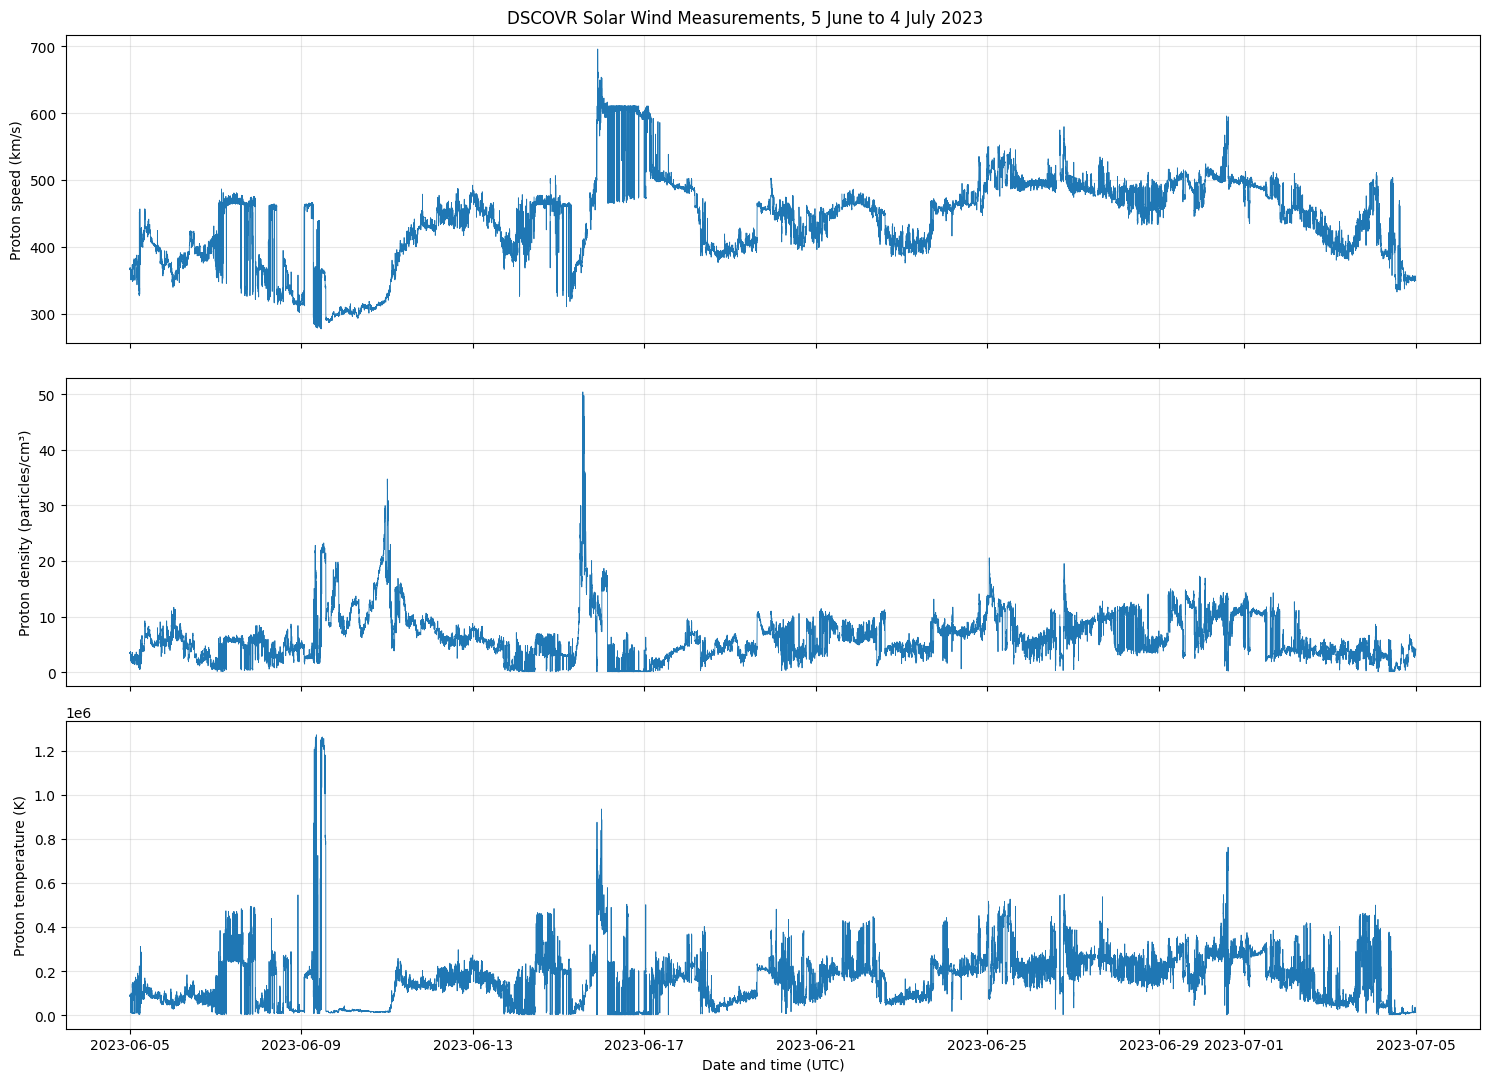

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Check missing values
print("MISSING VALUE COUNTS")
print(historical_df.isna().sum())

print("\nRows with missing measurements:")
print(historical_df[
    ["proton_speed", "proton_density", "proton_temperature"]
].isna().any(axis=1).sum())

# 2. Check time intervals
time_differences = historical_df["date"].diff().dropna()

print("\nTIME INTERVALS")
print(time_differences.value_counts().sort_index())

# Identify missing timestamps in the expected one-minute sequence
expected_times = pd.date_range(
    start=historical_df["date"].min(),
    end=historical_df["date"].max(),
    freq="1min"
)

missing_times = expected_times.difference(historical_df["date"])

print("\nMissing timestamps:", len(missing_times))
print("Examples of missing timestamps:")
print(missing_times[:10])

# 3. Statistical summary
print("\nPHYSICAL VARIABLE SUMMARY")
display(
    historical_df[
        ["proton_speed", "proton_density", "proton_temperature"]
    ].describe().round(2)
)

# 4. Plot the three physical variables
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)

variables = [
    ("proton_speed", "Proton speed (km/s)"),
    ("proton_density", "Proton density (particles/cm³)"),
    ("proton_temperature", "Proton temperature (K)")
]

for ax, (column, label) in zip(axes, variables):
    ax.plot(
        historical_df["date"],
        historical_df[column],
        linewidth=0.6
    )
    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date and time (UTC)")
fig.suptitle("DSCOVR Solar Wind Measurements, 5 June to 4 July 2023")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Ensure chronological order
data = historical_df.sort_values("date").copy()
data = data.set_index("date")

# Create five-minute lag features
for variable in ["proton_speed", "proton_density", "proton_temperature"]:
    for lag in range(5):
        data[f"{variable}_lag_{lag}"] = data[variable].shift(lag)

# Target: proton speed one minute ahead
data["target_speed"] = data["proton_speed"].shift(-1)

# Select all required features and target
feature_columns = [
    f"{variable}_lag_{lag}"
    for variable in ["proton_speed", "proton_density", "proton_temperature"]
    for lag in range(5)
]

required_columns = feature_columns + ["target_speed"]

# Keep only complete forecasting windows
forecast_data = data[required_columns].dropna().copy()

print("FORECASTING DATASET")
print("Total historical records:", len(historical_df))
print("Usable forecasting samples:", len(forecast_data))
print("Number of input features:", len(feature_columns))
print("Forecast horizon: 1 minute ahead")
print("Input history: previous 5 minutes")
print("First target time:", forecast_data.index.min() + pd.Timedelta(minutes=1))
print("Last target time:", forecast_data.index.max() + pd.Timedelta(minutes=1))

display(forecast_data.head())

FORECASTING DATASET
Total historical records: 43199
Usable forecasting samples: 42730
Number of input features: 15
Forecast horizon: 1 minute ahead
Input history: previous 5 minutes
First target time: 2023-06-05 00:05:00
Last target time: 2023-07-04 23:59:00


,proton_speed_lag_0,proton_speed_lag_1,proton_speed_lag_2,proton_speed_lag_3,proton_speed_lag_4,proton_density_lag_0,proton_density_lag_1,proton_density_lag_2,proton_density_lag_3,proton_density_lag_4,proton_temperature_lag_0,proton_temperature_lag_1,proton_temperature_lag_2,proton_temperature_lag_3,proton_temperature_lag_4,target_speed
date,,,,,,,,,,,,,,,,
2023-06-05 00:04:00,365.299988,365.399994,367.299988,366.700012,366.700012,3.42,3.47,3.51,3.42,3.33,89376.0,90952.0,84378.0,83856.0,84834.0,367.399994
2023-06-05 00:05:00,367.399994,365.299988,365.399994,367.299988,366.700012,3.44,3.42,3.47,3.51,3.42,91822.0,89376.0,90952.0,84378.0,83856.0,368.399994
2023-06-05 00:06:00,368.399994,367.399994,365.299988,365.399994,367.299988,3.41,3.44,3.42,3.47,3.51,87709.0,91822.0,89376.0,90952.0,84378.0,368.899994
2023-06-05 00:07:00,368.899994,368.399994,367.399994,365.299988,365.399994,3.52,3.41,3.44,3.42,3.47,91603.0,87709.0,91822.0,89376.0,90952.0,367.799988
2023-06-05 00:08:00,367.799988,368.899994,368.399994,367.399994,365.299988,3.47,3.52,3.41,3.44,3.42,93308.0,91603.0,87709.0,91822.0,89376.0,367.399994


In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare features and target
X = forecast_data[feature_columns]
y = forecast_data["target_speed"]

# Chronological split: 70% training, 15% validation, 15% testing
n = len(forecast_data)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:validation_end]
y_val = y.iloc[train_end:validation_end]

X_test = X.iloc[validation_end:]
y_test = y.iloc[validation_end:]

print("DATA SPLIT")
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTIME PERIODS")
print("Training:", X_train.index.min(), "to", X_train.index.max())
print("Validation:", X_val.index.min(), "to", X_val.index.max())
print("Testing:", X_test.index.min(), "to", X_test.index.max())

# Define models
models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=42
    )
}

# Persistence baseline
validation_predictions = {
    "Persistence": X_val["proton_speed_lag_0"].values
}

# Train and evaluate on validation data
for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    validation_predictions[name] = model.predict(X_val)

# Calculate validation metrics
results = []

for name, predictions in validation_predictions.items():
    results.append({
        "Model": name,
        "MAE (km/s)": mean_absolute_error(y_val, predictions),
        "RMSE (km/s)": np.sqrt(mean_squared_error(y_val, predictions)),
        "R²": r2_score(y_val, predictions)
    })

validation_results = pd.DataFrame(results).sort_values("MAE (km/s)")

print("\nVALIDATION RESULTS")
display(validation_results.round(4))

DATA SPLIT
Training samples: 29910
Validation samples: 6410
Testing samples: 6410

TIME PERIODS
Training: 2023-06-05 00:04:00 to 2023-06-25 22:36:00
Validation: 2023-06-25 22:37:00 to 2023-06-30 13:01:00
Testing: 2023-06-30 13:02:00 to 2023-07-04 23:58:00
Training: Linear Regression
Training: Random Forest
Training: HistGradientBoosting

VALIDATION RESULTS


,Model,MAE (km/s),RMSE (km/s),R²
0,Persistence,3.6018,6.3910,0.8841
1,Linear Regression,3.6747,6.1833,0.8915
2,Random Forest,4.3362,7.0609,0.8586
3,HistGradientBoosting,4.4910,7.1090,0.8566


In [ ]:
# CHECK FOR MISSING MINUTES IN THE HISTORICAL DATA

historical_df = historical_df.sort_values("date").copy()

time_differences = historical_df["date"].diff()

print("TIME INTERVALS")
print(time_differences.value_counts().sort_index())

print("\nINTERVALS LONGER THAN ONE MINUTE:")
print(time_differences[time_differences > pd.Timedelta(minutes=1)].value_counts())

print("\nTOTAL MISSING MINUTES:")

expected_index = pd.date_range(
    start=historical_df["date"].min(),
    end=historical_df["date"].max(),
    freq="1min"
)

missing_timestamps = expected_index.difference(
    pd.DatetimeIndex(historical_df["date"])
)

print(len(missing_timestamps))

print("\nFIRST MISSING TIMESTAMPS:")
print(missing_timestamps[:10])

TIME INTERVALS
date
0 days 00:01:00    43197
0 days 00:02:00        1
Name: count, dtype: int64

INTERVALS LONGER THAN ONE MINUTE:
date
0 days 00:02:00    1
Name: count, dtype: int64

TOTAL MISSING MINUTES:
1

FIRST MISSING TIMESTAMPS:
DatetimeIndex(['2023-07-01 00:00:00'], dtype='datetime64[ns]', freq='min')


In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Restore the complete one-minute timeline
data = historical_df.sort_values("date").copy()
data = data.set_index("date")

full_index = pd.date_range(
    start=data.index.min(),
    end=data.index.max(),
    freq="1min"
)

data = data.reindex(full_index)
data.index.name = "date"

# 2. Create the input features and next-minute target
variables = [
    "proton_speed",
    "proton_density",
    "proton_temperature"
]

for variable in variables:
    for lag in range(5):
        data[f"{variable}_lag_{lag}"] = data[variable].shift(lag)

data["target_speed"] = data["proton_speed"].shift(-1)

feature_columns = [
    f"{variable}_lag_{lag}"
    for variable in variables
    for lag in range(5)
]

required_columns = feature_columns + ["target_speed"]

forecast_data = data[required_columns].dropna().copy()

print("CORRECTED DATASET")
print("Historical timestamps:", len(data))
print("Missing timestamps:", data.index.isna().sum())
print("Usable forecasting samples:", len(forecast_data))
print("Input features:", len(feature_columns))
print("Forecast horizon: 1 minute")

# 3. Chronological split
X = forecast_data[feature_columns]
y = forecast_data["target_speed"]

n = len(forecast_data)
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:validation_end]
y_val = y.iloc[train_end:validation_end]

X_test = X.iloc[validation_end:]
y_test = y.iloc[validation_end:]

print("\nDATA SPLIT")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nTIME PERIODS")
print("Training:", X_train.index.min(), "to", X_train.index.max())
print("Validation:", X_val.index.min(), "to", X_val.index.max())
print("Testing:", X_test.index.min(), "to", X_test.index.max())

# 4. Train models and evaluate on validation data
models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=42
    )
}

validation_predictions = {
    "Persistence": X_val["proton_speed_lag_0"].values
}

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    validation_predictions[name] = model.predict(X_val)

results = []

for name, predictions in validation_predictions.items():
    results.append({
        "Model": name,
        "MAE (km/s)": mean_absolute_error(y_val, predictions),
        "RMSE (km/s)": np.sqrt(mean_squared_error(y_val, predictions)),
        "R²": r2_score(y_val, predictions)
    })

validation_results = pd.DataFrame(results).sort_values("MAE (km/s)")

print("\nCORRECTED VALIDATION RESULTS")
display(validation_results.round(4))

CORRECTED DATASET
Historical timestamps: 43200
Missing timestamps: 0
Usable forecasting samples: 42725
Input features: 15
Forecast horizon: 1 minute

DATA SPLIT
Training: 29907
Validation: 6409
Testing: 6409

TIME PERIODS
Training: 2023-06-05 00:04:00 to 2023-06-25 22:33:00
Validation: 2023-06-25 22:34:00 to 2023-06-30 12:57:00
Testing: 2023-06-30 12:58:00 to 2023-07-04 23:58:00
Training: Linear Regression
Training: Random Forest
Training: HistGradientBoosting

CORRECTED VALIDATION RESULTS


,Model,MAE (km/s),RMSE (km/s),R²
0,Persistence,3.5827,6.3219,0.8860
1,Linear Regression,3.6571,6.1344,0.8927
2,Random Forest,4.3197,7.0041,0.8601
3,HistGradientBoosting,4.6731,7.5652,0.8368


In [ ]:
# COMPARE SPEED-ONLY AND MULTIVARIABLE INPUTS

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Define two feature groups
speed_features = [
    f"proton_speed_lag_{lag}" for lag in range(5)
]

all_features = feature_columns

# Use the same chronological split for both experiments
def evaluate_feature_set(features, experiment_name):

    X = forecast_data[features]
    y = forecast_data["target_speed"]

    n = len(forecast_data)
    train_end = int(n * 0.70)
    validation_end = int(n * 0.85)

    X_train = X.iloc[:train_end]
    y_train = y.iloc[:train_end]

    X_val = X.iloc[train_end:validation_end]
    y_val = y.iloc[train_end:validation_end]

    models = {
        "Persistence": None,
        "Linear Regression": make_pipeline(
            StandardScaler(), LinearRegression()
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ),
        "HistGradientBoosting": HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=31,
            random_state=42
        )
    }

    results = []

    for name, model in models.items():

        if name == "Persistence":
            predictions = X_val["proton_speed_lag_0"].values
        else:
            model.fit(X_train, y_train)
            predictions = model.predict(X_val)

        results.append({
            "Experiment": experiment_name,
            "Model": name,
            "MAE (km/s)": mean_absolute_error(y_val, predictions),
            "RMSE (km/s)": np.sqrt(
                mean_squared_error(y_val, predictions)
            ),
            "R²": r2_score(y_val, predictions)
        })

    return results


results_speed = evaluate_feature_set(
    speed_features, "Speed only"
)

results_all = evaluate_feature_set(
    all_features, "Speed + Density + Temperature"
)

feature_comparison = pd.DataFrame(
    results_speed + results_all
)

display(
    feature_comparison.sort_values(
        ["Model", "Experiment"]
    ).round(4)
)

,Experiment,Model,MAE (km/s),RMSE (km/s),R²
7,Speed + Density + Temperature,HistGradientBoosting,4.6731,7.5652,0.8368
3,Speed only,HistGradientBoosting,4.0874,6.6907,0.8723
5,Speed + Density + Temperature,Linear Regression,3.6571,6.1344,0.8927
1,Speed only,Linear Regression,3.6529,6.1796,0.8911
4,Speed + Density + Temperature,Persistence,3.5827,6.3219,0.8860
0,Speed only,Persistence,3.5827,6.3219,0.8860
6,Speed + Density + Temperature,Random Forest,4.3197,7.0041,0.8601
2,Speed only,Random Forest,4.0104,6.8308,0.8669


In [ ]:
# FINAL TEST EVALUATION

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Training and validation data combined
X_train_val_speed = forecast_data[speed_features].iloc[:validation_end]
X_train_val_all = forecast_data[feature_columns].iloc[:validation_end]
y_train_val = forecast_data["target_speed"].iloc[:validation_end]

# Untouched test data
X_test_speed = forecast_data[speed_features].iloc[validation_end:]
X_test_all = forecast_data[feature_columns].iloc[validation_end:]
y_test = forecast_data["target_speed"].iloc[validation_end:]

# Train selected models
linear_speed = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_all = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_speed.fit(X_train_val_speed, y_train_val)
linear_all.fit(X_train_val_all, y_train_val)

# Predictions
test_predictions = {
    "Persistence": X_test_all["proton_speed_lag_0"].values,
    "Linear Regression (Speed only)": linear_speed.predict(X_test_speed),
    "Linear Regression (All variables)": linear_all.predict(X_test_all)
}

# Final metrics
test_results = []

for name, predictions in test_predictions.items():
    test_results.append({
        "Model": name,
        "MAE (km/s)": mean_absolute_error(y_test, predictions),
        "RMSE (km/s)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions)
    })

final_test_results = pd.DataFrame(test_results)

print("FINAL TEST RESULTS")
display(final_test_results.round(4))

FINAL TEST RESULTS


,Model,MAE (km/s),RMSE (km/s),R²
0,Persistence,3.9186,9.0512,0.9653
1,Linear Regression (Speed only),3.9683,8.5231,0.9692
2,Linear Regression (All variables),3.9561,8.4783,0.9695


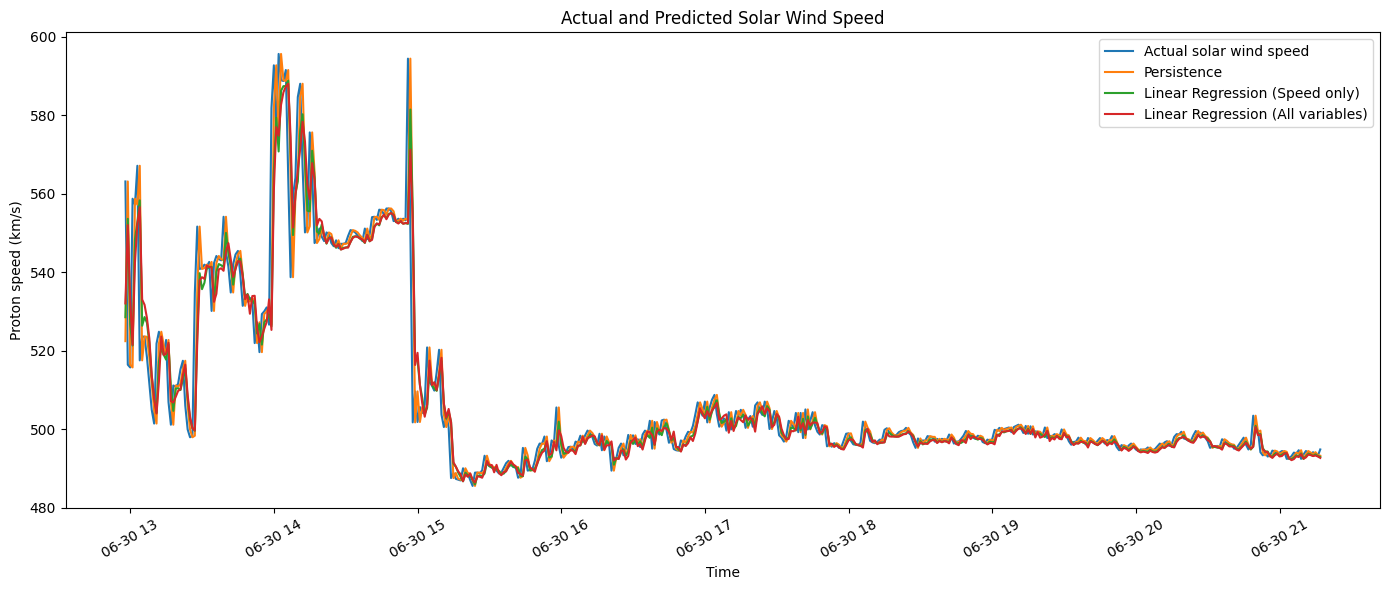

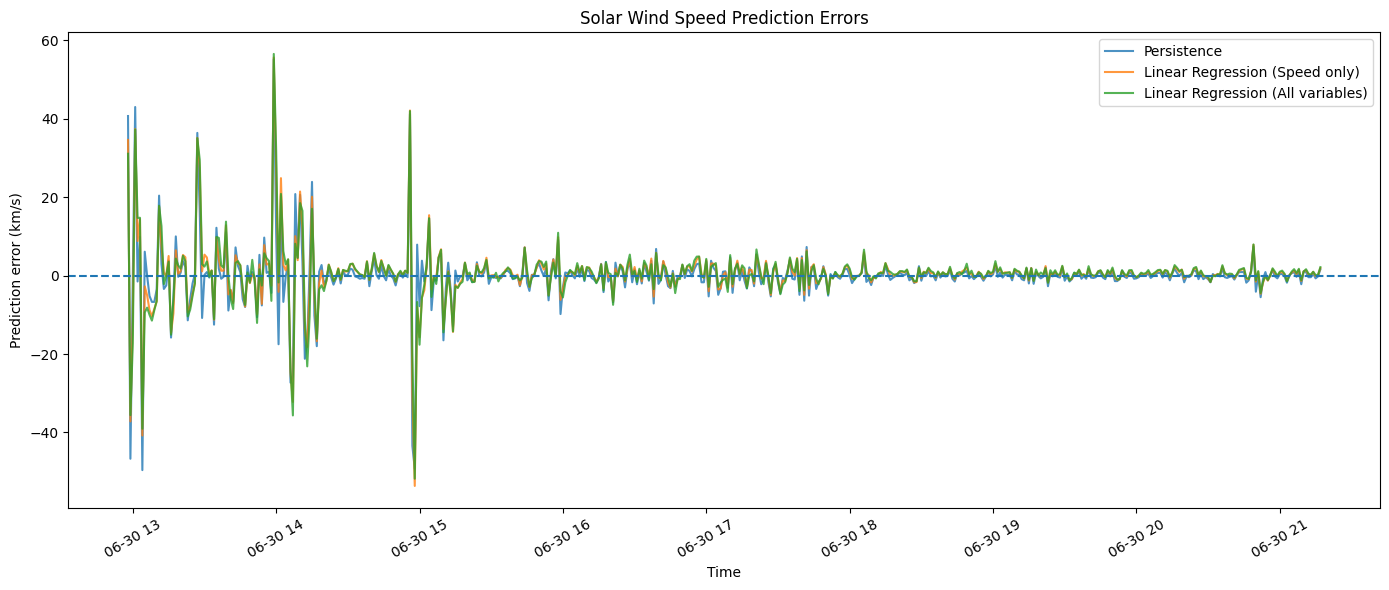

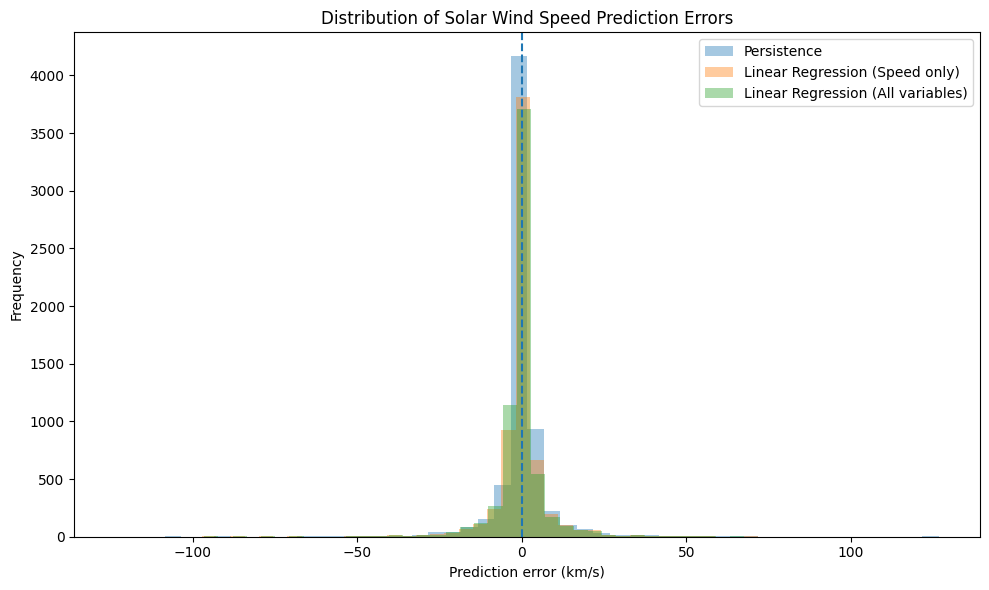

RESEARCH FIGURES AND RESULTS SAVED
figure1_actual_vs_predicted.png
figure2_prediction_errors.png
figure3_error_distribution.png
final_test_results.csv


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Prepare results
actual = y_test.values
timestamps = y_test.index

errors = {
    name: actual - predictions
    for name, predictions in test_predictions.items()
}

# FIGURE 1: Actual versus predicted speed
plt.figure(figsize=(14, 6))

sample_size = min(500, len(actual))

plt.plot(
    timestamps[:sample_size],
    actual[:sample_size],
    label="Actual solar wind speed"
)

plt.plot(
    timestamps[:sample_size],
    test_predictions["Persistence"][:sample_size],
    label="Persistence"
)

plt.plot(
    timestamps[:sample_size],
    test_predictions["Linear Regression (Speed only)"][:sample_size],
    label="Linear Regression (Speed only)"
)

plt.plot(
    timestamps[:sample_size],
    test_predictions["Linear Regression (All variables)"][:sample_size],
    label="Linear Regression (All variables)"
)

plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.title("Actual and Predicted Solar Wind Speed")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("figure1_actual_vs_predicted.png", dpi=300)
plt.show()


# FIGURE 2: Prediction errors over time
plt.figure(figsize=(14, 6))

for name, error in errors.items():
    plt.plot(
        timestamps[:sample_size],
        error[:sample_size],
        label=name,
        alpha=0.8
    )

plt.axhline(0, linestyle="--")
plt.xlabel("Time")
plt.ylabel("Prediction error (km/s)")
plt.title("Solar Wind Speed Prediction Errors")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("figure2_prediction_errors.png", dpi=300)
plt.show()


# FIGURE 3: Distribution of prediction errors
plt.figure(figsize=(10, 6))

for name, error in errors.items():
    plt.hist(
        error,
        bins=50,
        alpha=0.4,
        label=name
    )

plt.axvline(0, linestyle="--")
plt.xlabel("Prediction error (km/s)")
plt.ylabel("Frequency")
plt.title("Distribution of Solar Wind Speed Prediction Errors")
plt.legend()
plt.tight_layout()
plt.savefig("figure3_error_distribution.png", dpi=300)
plt.show()


# Save final test metrics
final_test_results.to_csv("final_test_results.csv", index=False)

print("RESEARCH FIGURES AND RESULTS SAVED")
print("figure1_actual_vs_predicted.png")
print("figure2_prediction_errors.png")
print("figure3_error_distribution.png")
print("final_test_results.csv")